# Track B: Statistical Investigation of Hospital Encounter Costs

**Project:** Hospital Operations, Cost & Patient Flow Intelligence (AnalystLab Africa Experience Lab, Week 3)
**Author:** NZAU

This notebook uses the cleaned tables produced by `src/prepare_data.py`. Run that script first (see Section 7 for the full steps). All figures are saved to `docs/figures/`.

## 1. Research question and variables

**Research question:** How do recorded encounter claim costs vary across encounter classes, and are they associated with encounter duration?

**Why it matters:** Claim cost is the main financial measure for each encounter. Knowing how cost differs by encounter type, and whether longer encounters cost more, helps operations and finance managers decide where to review cost and plan resources.

**Unit of analysis:** one encounter (one row of `fact_encounters`).

| Variable | Role | Type | Notes |
|---|---|---|---|
| `total_claim_cost` | Outcome | Continuous, never negative, very right-skewed | 89 encounters have a cost of 0 and are kept |
| `encounter_class` | Explanatory (H1) | Categorical, 6 groups | Unequal group sizes (1,135 to 12,537) |
| `duration_hours` | Explanatory (H2) | Continuous | Only rows with `duration_valid = True` are used (27,887 rows) |
| `is_insured` | Explanatory (H3) | Binary | Payer `NO_INSURANCE` versus all other payers |

**Data decisions carried over from the data-quality assessment (`docs/01_data_quality_assessment.md`):** the four encounters with durations over one year are excluded from duration analysis only. Zero values are kept and flagged. Nothing is imputed.

**Hypotheses:** H1 claim costs differ across encounter classes. H2 claim cost is associated with duration. H3 claim costs differ between insured and uninsured encounters. The formal wording is in Section 4.

In [1]:
from pathlib import Path
import platform
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
from statsmodels.stats.multitest import multipletests

# Versions, so the analysis can be reproduced
print("Python      :", platform.python_version())
for name, mod in [("pandas", pd), ("numpy", np), ("matplotlib", matplotlib),
                  ("seaborn", sns), ("scipy", scipy), ("statsmodels", statsmodels)]:
    print(f"{name:<12}:", mod.__version__)

# Find the project folder, whether the notebook runs from notebooks/ or the root
cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
PROCESSED = ROOT / "data" / "processed"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

print("\nProject root:", ROOT.name)
for f in ["fact_encounters.csv", "fact_procedures.csv", "dim_patients.csv",
          "dim_payers.csv", "dim_organizations.csv"]:
    print(f"  {f:<24}", "found" if (PROCESSED / f).exists() else "MISSING")

# Settings used throughout
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42     # fixed, so sampled results repeat exactly
ALPHA = 0.05          # significance level
results = {}          # collects the key results for the summary table


def fmt_p(p):
    """Format a p-value. Very small values underflow to 0 in floating point."""
    return "< 1e-300" if p == 0 else f"{p:.2e}"


def p_text(p):
    """p-value wording for sentences: 'p < 1e-300' or 'p = 2.3e-05'."""
    return "< 1e-300" if p == 0 else f"= {p:.2e}"


def epsilon_squared(H, n):
    """Effect size for the Kruskal-Wallis test (0 = none, 1 = maximum)."""
    return H * (n + 1) / (n ** 2 - 1)


def spearman_ci(rho, n):
    """Approximate 95% confidence interval for a Spearman correlation (Fisher z)."""
    z = np.arctanh(rho)
    se = 1.06 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)


Python      : 3.13.15
pandas      : 3.1.1
numpy       : 2.5.5
matplotlib  : 3.11.2
seaborn     : 0.13.2
scipy       : 1.18.1
statsmodels : 0.15.0

Project root: week3-hospital-operations
  fact_encounters.csv      found
  fact_procedures.csv      found
  dim_patients.csv         found
  dim_payers.csv           found
  dim_organizations.csv    found


## 2. Data and data-quality summary

The data are the five cleaned tables from `src/prepare_data.py`. Only `fact_encounters` is needed here. Patient names and addresses were never loaded, and the identifier codes are not displayed.

In [2]:
use_cols = ["encounter_id", "patient_id", "payer_name", "is_insured", "encounter_class",
            "year", "is_partial_year", "base_encounter_cost", "total_claim_cost",
            "payer_coverage", "zero_total_claim", "zero_recorded_coverage",
            "duration_hours", "duration_valid", "over_24h"]

enc = pd.read_csv(PROCESSED / "fact_encounters.csv", usecols=use_cols)
print("Rows, columns:", enc.shape)
enc.drop(columns=["encounter_id", "patient_id"]).head()   # identifier codes are not displayed

Rows, columns: (27891, 15)


,year,is_partial_year,payer_name,is_insured,encounter_class,base_encounter_cost,total_claim_cost,payer_coverage,zero_total_claim,zero_recorded_coverage,duration_hours,duration_valid,over_24h
0,2011,False,NO_INSURANCE,False,ambulatory,85.55,1018.02,0.00,False,True,3.533333,True,False
1,2011,False,NO_INSURANCE,False,outpatient,142.58,2619.36,0.00,False,True,0.284167,True,False
2,2011,False,Medicare,True,outpatient,85.55,461.59,305.27,False,False,0.250000,True,False
3,2011,False,NO_INSURANCE,False,wellness,136.80,1784.24,0.00,False,True,0.250000,True,False
4,2011,False,Anthem,True,ambulatory,85.55,234.72,0.00,False,True,0.250000,True,False


### Data types and missing values

In [3]:
quality = pd.DataFrame({
    "dtype": enc.dtypes.astype(str),
    "missing": enc.isna().sum(),
    "missing_%": (enc.isna().mean() * 100).round(2),
})
quality

,dtype,missing,missing_%
encounter_id,str,0,0.0
year,int64,0,0.0
is_partial_year,bool,0,0.0
patient_id,str,0,0.0
payer_name,str,0,0.0
is_insured,bool,0,0.0
encounter_class,str,0,0.0
base_encounter_cost,float64,0,0.0
total_claim_cost,float64,0,0.0
payer_coverage,float64,0,0.0


### Duplicates, repeated patients, flags and consistency checks

In [4]:
print("Unique encounter_id :", enc.encounter_id.nunique(), "| duplicates:", enc.encounter_id.duplicated().sum())
print("Unique patients     :", enc.patient_id.nunique())
per_patient = enc.groupby("patient_id").size()
print("Encounters/patient  : median", per_patient.median(), "| max", per_patient.max())
print()
print(enc.encounter_class.value_counts().to_string())
print()
print("duration_valid = False :", (~enc.duration_valid).sum())
print("zero_total_claim       :", enc.zero_total_claim.sum())
print("partial-year rows      :", enc.is_partial_year.sum())
print("zero_recorded_coverage :", enc.zero_recorded_coverage.sum())
print()

# Consistency checks
print("Negative costs                    :", (enc[["base_encounter_cost", "total_claim_cost", "payer_coverage"]] < 0).sum().sum())
print("Payer coverage above claim cost   :", (enc.payer_coverage > enc.total_claim_cost).sum())
print("Zero-duration encounters          :", (enc.duration_hours == 0).sum())
print()
enc[["total_claim_cost", "duration_hours"]].describe().round(2)

Unique encounter_id : 27891 | duplicates: 0
Unique patients     : 974
Encounters/patient  : median 14.0 | max 1381

encounter_class
ambulatory    12537
outpatient     6300
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1135

duration_valid = False : 4
zero_total_claim       : 89
partial-year rows      : 220
zero_recorded_coverage : 13586



Negative costs                    : 0
Payer coverage above claim cost   : 0
Zero-duration encounters          : 0



,total_claim_cost,duration_hours
count,27891.00,27891.00
mean,3639.68,7.27
std,9205.60,398.32
min,0.00,0.25
25%,142.58,0.25
50%,278.58,0.25
75%,1412.53,0.86
max,641882.70,44930.00


### Data-quality summary

| Check | Result | What was done |
|---|---|---|
| Rows and columns | 27,891 encounters, 15 columns used | |
| Missing values | None in any column used | Nothing to impute |
| Duplicate encounters | 0 | |
| Negative costs | 0 | |
| Payer coverage above claim cost | 0 | |
| Zero-cost encounters | 89 | Kept and flagged. Meaning of zero is unknown, so removal would be a guess |
| Invalid durations (over one year) | 4 | Excluded from the duration analysis (H2) only |
| Partial final year (2022) | 220 encounters | Kept. Year is not used in any test here |
| Zero recorded payer coverage | 13,586 | Not used as an outcome. It is not the same as "uninsured" |

**Two features of the data shape the statistics:**

1. **Repeated patients.** 974 patients account for 27,891 encounters. The median patient has 14 encounters, and one patient has 1,381 (5.0% of all rows). Encounters from the same patient are not independent observations.
2. **Repeated cost values.** There are only 13,529 distinct claim costs across 27,891 encounters, and 69% of encounters last exactly 15 minutes. Many values are tied, which matters for rank-based tests.

## 3. Exploratory analysis

Seven views of the data: cost distribution, cost by class, outliers, duration, duration against cost, repeated patients, and insurance status.

### 3.1 Distribution of claim cost

mean 3,639.68 | median 278.58 | skewness 16.27 | kurtosis 895.69
0.500      278.58
0.750     1412.53
0.900    12888.58
0.950    20785.89
0.990    37286.68
0.999    60351.99
Share of encounters below the mean: 81.2 %
Zero-cost encounters: 89
Maximum is 2304 times the median
Distinct cost values: 13529 across 27891 encounters


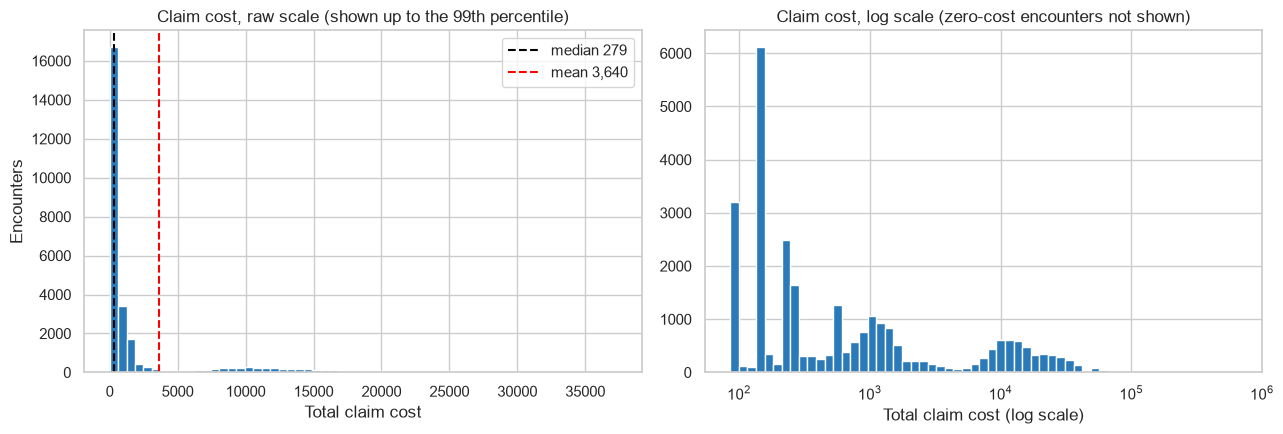

In [5]:
cost = enc["total_claim_cost"]
print(f"mean {cost.mean():,.2f} | median {cost.median():,.2f} | "
      f"skewness {stats.skew(cost):.2f} | kurtosis {stats.kurtosis(cost):.2f}")
print(cost.quantile([.5, .75, .9, .95, .99, .999]).round(2).to_string())
print("Share of encounters below the mean:", round((cost < cost.mean()).mean() * 100, 1), "%")
print("Zero-cost encounters:", (cost == 0).sum())
print("Maximum is", round(cost.max() / cost.median()), "times the median")
print("Distinct cost values:", cost.nunique(), "across", len(cost), "encounters")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: raw scale, cut at the 99th percentile so the bars are visible
ax[0].hist(cost[cost <= cost.quantile(.99)], bins=60, color="#2a7ab9")
ax[0].axvline(cost.median(), color="black", ls="--", label=f"median {cost.median():,.0f}")
ax[0].axvline(cost.mean(), color="red", ls="--", label=f"mean {cost.mean():,.0f}")
ax[0].set_title("Claim cost, raw scale (shown up to the 99th percentile)")
ax[0].set_xlabel("Total claim cost")
ax[0].set_ylabel("Encounters")
ax[0].legend()

# Right: log scale, so the whole range can be seen
pos = cost[cost > 0]
ax[1].hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 60), color="#2a7ab9")
ax[1].set_xscale("log")
ax[1].set_title("Claim cost, log scale (zero-cost encounters not shown)")
ax[1].set_xlabel("Total claim cost (log scale)")

plt.tight_layout()
plt.savefig(FIG / "fig01_claim_cost_distribution.png", dpi=150)
plt.show()

**What the figure shows**

- Claim cost is extremely right-skewed (skewness 16.27, kurtosis 895.69). The mean (3,639.68) is 13 times the median (278.58), 81.2% of encounters cost less than the mean, and the most expensive encounter is 2,304 times the median.
- On the raw scale (left), nearly all encounters sit in the first bar, and the red mean line is far to the right of the black median line.
- On the log scale (right), the distribution is **not one smooth hill**. It has several separate peaks (roughly near 100, 150, 250, 600, 1,000 and 10,000). The data look like a mixture of different kinds of encounters, each with typical charges.
- It is not normal even after a log transform (Shapiro-Wilk W = 0.887 on the log scale, tested in Section 4).

**What it means for the analysis:** averages are misleading here, and methods that assume normal data are not appropriate. Rank-based tests are used instead.

**What it cannot establish:** why the peaks exist. The data do not say which services or charges produce each cluster.

### 3.2 Claim cost by encounter class

,n,median,mean,q1,q3,zero_cost
encounter_class,,,,,,
inpatient,1135,2355.59,7761.35,313.96,14092.26,28
wellness,1931,1231.44,4260.71,853.36,1643.68,51
ambulatory,12537,573.98,2894.11,142.58,1267.08,4
outpatient,6300,278.58,2237.30,153.89,594.45,0
emergency,2322,146.18,4629.65,146.18,4288.38,6
urgentcare,3666,142.58,6369.16,142.58,8921.38,0


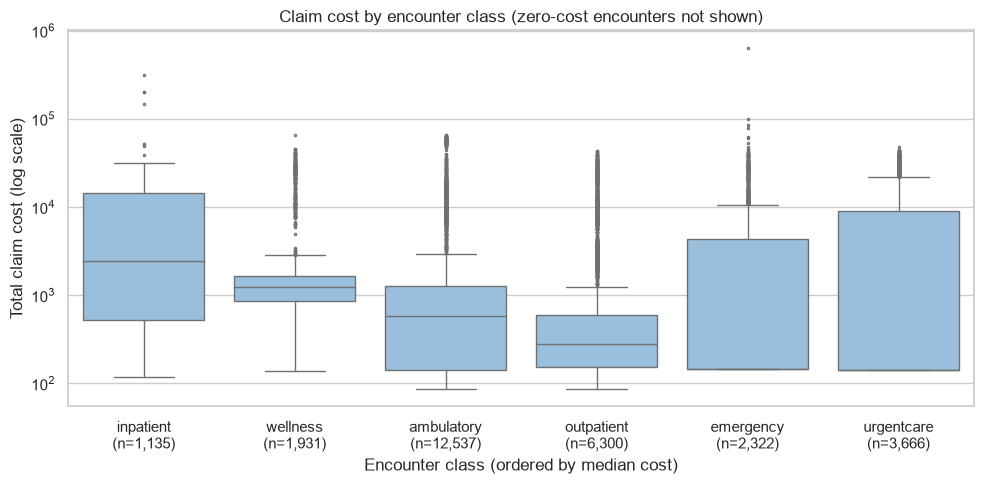

In [6]:
order = (enc.groupby("encounter_class")["total_claim_cost"].median()
         .sort_values(ascending=False).index.tolist())

summary = (enc.groupby("encounter_class")["total_claim_cost"]
           .agg(n="size", median="median", mean="mean",
                q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75),
                zero_cost=lambda s: (s == 0).sum())
           .loc[order].round(2))
display(summary)

pos = enc[enc.total_claim_cost > 0]
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=pos, x="encounter_class", y="total_claim_cost", order=order,
            color="#8ec1e8", fliersize=1.5, linewidth=1, ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Encounter class (ordered by median cost)")
ax.set_ylabel("Total claim cost (log scale)")
ax.set_title("Claim cost by encounter class (zero-cost encounters not shown)")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{c}\n(n={summary.loc[c, 'n']:,})" for c in order])
plt.tight_layout()
plt.savefig(FIG / "fig02_cost_by_class.png", dpi=150)
plt.show()

**What the table and figure show**

- Median cost, highest to lowest: inpatient 2,355.59, wellness 1,231.44, ambulatory 573.98, outpatient 278.58, emergency 146.18, urgent care 142.58.
- The order by **mean** is different (inpatient 7,761, urgent care 6,369, emergency 4,630, wellness 4,261, ambulatory 2,894, outpatient 2,237). Emergency and urgent care have low medians but very wide upper ranges: three quarters of urgent care encounters cost under 8,921, yet a quarter cost more, and the lowest quarter is all around 143. These classes are a mix of many cheap encounters and a minority of very expensive ones.
- Wellness is the tightest group (middle half between 853 and 1,644).
- Group sizes are very unequal, from 1,135 (inpatient) to 12,537 (ambulatory).

**What it cannot establish:** whether the differences are larger than chance. That is tested in H1 (Section 4).

### 3.3 Outliers

In [7]:
q1, q3 = cost.quantile([.25, .75])
fence = q3 + 1.5 * (q3 - q1)
above = cost > fence
print(f"IQR rule: upper fence = {fence:,.2f}")
print(f"Encounters above the fence: {above.sum():,} ({above.mean() * 100:.1f}%), "
      f"carrying {cost[above].sum() / cost.sum() * 100:.1f}% of all claim cost")

s = cost.sort_values(ascending=False)
for pct in (0.01, 0.05, 0.10):
    k = int(len(s) * pct)
    print(f"Top {int(pct * 100):>2}% of encounters ({k:,}) carry {s.iloc[:k].sum() / cost.sum() * 100:.1f}% of cost")

print("\nShare of each class above the overall fence:")
print((enc.assign(above=above).groupby("encounter_class")["above"].mean() * 100).round(1)
      .sort_values(ascending=False).to_string())

IQR rule: upper fence = 3,317.46
Encounters above the fence: 5,316 (19.1%), carrying 89.1% of all claim cost
Top  1% of encounters (278) carry 14.5% of cost
Top  5% of encounters (1,394) carry 44.6% of cost
Top 10% of encounters (2,789) carry 66.6% of cost

Share of each class above the overall fence:
encounter_class
inpatient     44.1
urgentcare    27.4
emergency     25.5
ambulatory    16.5
wellness      15.5
outpatient    13.5


**What the output shows**

- By the usual IQR rule, 5,316 encounters (19.1%) are "outliers" (above 3,317.46), and they carry 89.1% of all claim cost. The most expensive 1% of encounters carry 14.5% of cost, the top 5% carry 44.6%, and the top 10% carry 66.6%.
- Inpatient has the largest share above the fence (44.1%), followed by urgent care (27.4%) and emergency (25.5%).

**Decision:** these values are **kept**. They are not errors: no cost is negative, coverage never exceeds the claim, and the high values form clusters (Section 3.1) rather than isolated impossible points. Removing them would remove most of the money. Instead, rank-based methods are used, because they limit the influence of extreme values without deleting any data.

### 3.4 Encounter duration

Valid-duration encounters: 27,887
Exactly 0.25 hours (15 minutes): 19,313 (69.3%)
Distinct duration values: 1,773
Median 0.25 h | 90th percentile 2.80 h | maximum 8,352 h


,n,min,median,max,share_exactly_15min
encounter_class,,,,,
inpatient,1135,24.00,24.00,8250.004167,0.0
wellness,1931,0.25,0.25,0.250000,100.0
ambulatory,12534,0.25,0.25,7239.212778,63.4
outpatient,6299,0.25,0.25,8352.000000,91.6
emergency,2322,1.00,1.00,589.000000,0.0
urgentcare,3666,0.25,0.25,0.250000,100.0


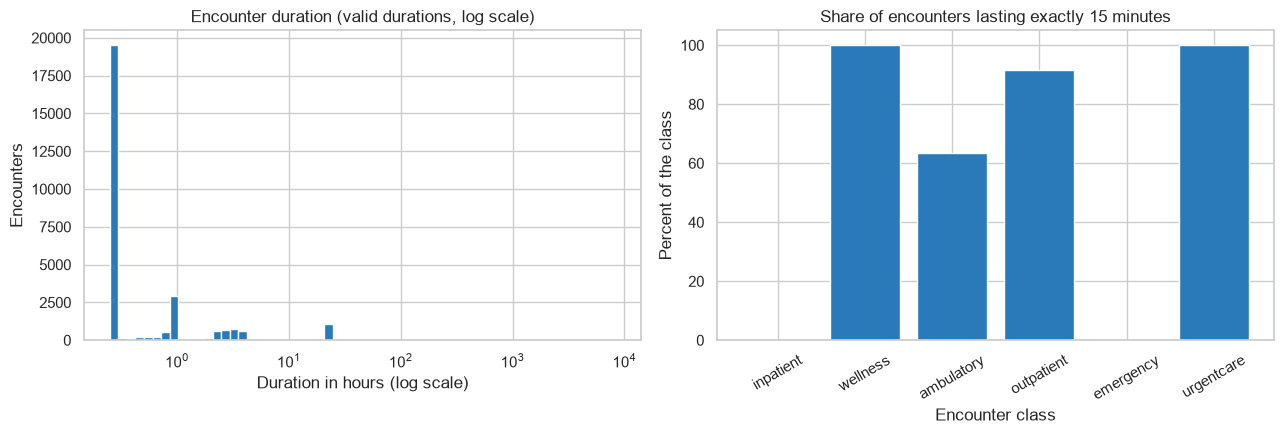

In [8]:
valid = enc[enc.duration_valid].copy()
dur = valid["duration_hours"]
share_15 = (dur == 0.25).mean() * 100
print(f"Valid-duration encounters: {len(valid):,}")
print(f"Exactly 0.25 hours (15 minutes): {(dur == 0.25).sum():,} ({share_15:.1f}%)")
print(f"Distinct duration values: {dur.nunique():,}")
print(f"Median {dur.median():.2f} h | 90th percentile {dur.quantile(.9):.2f} h | maximum {dur.max():,.0f} h")

by_class = valid.groupby("encounter_class")["duration_hours"].agg(
    n="size", min="min", median="median", max="max",
    share_exactly_15min=lambda s: round((s == 0.25).mean() * 100, 1))
display(by_class.loc[order])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(dur, bins=np.logspace(np.log10(dur.min()), np.log10(dur.max()), 60), color="#2a7ab9")
ax[0].set_xscale("log")
ax[0].set_title("Encounter duration (valid durations, log scale)")
ax[0].set_xlabel("Duration in hours (log scale)")
ax[0].set_ylabel("Encounters")

share = valid.groupby("encounter_class")["duration_hours"].apply(lambda s: (s == 0.25).mean() * 100).loc[order]
ax[1].bar(share.index, share.values, color="#2a7ab9")
ax[1].set_title("Share of encounters lasting exactly 15 minutes")
ax[1].set_ylabel("Percent of the class")
ax[1].set_xlabel("Encounter class")
plt.setp(ax[1].get_xticklabels(), rotation=30)
plt.tight_layout()
plt.savefig(FIG / "fig03_duration_distribution.png", dpi=150)
plt.show()

**What the output shows**

- 69.3% of valid encounters last **exactly 15 minutes** (0.25 hours), and there are only 1,773 distinct durations.
- Duration is largely **set by encounter class**: wellness and urgent care are 100% at 15 minutes, outpatient 91.6%, ambulatory 63.4%, emergency starts at exactly 1 hour, and inpatient starts at exactly 24 hours (median 24).
- Some durations that pass the one-year rule are still very long (up to 8,352 hours, about 348 days). They are kept because they are below the one-year limit, and rank-based methods limit their influence.

**What it means for H2:** because duration depends so heavily on class, any link between duration and cost could simply reflect class. H2 is therefore also tested **within** each class. Wellness and urgent care have no variation in duration, so no correlation can be calculated for them.

### 3.5 Claim cost against duration

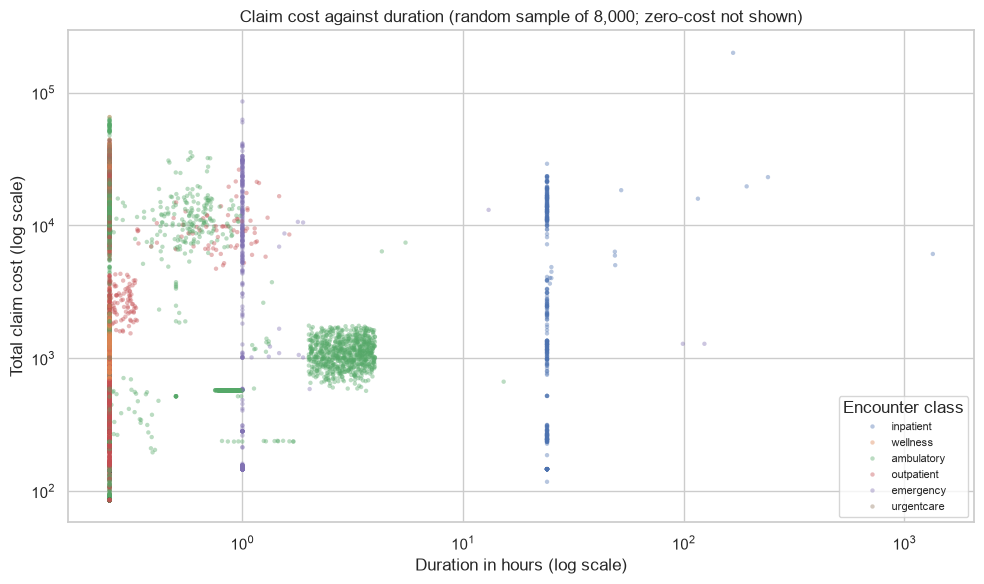

In [9]:
sample = valid[valid.total_claim_cost > 0].sample(8000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample, x="duration_hours", y="total_claim_cost", hue="encounter_class",
                hue_order=order, s=10, alpha=0.4, linewidth=0, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Duration in hours (log scale)")
ax.set_ylabel("Total claim cost (log scale)")
ax.set_title("Claim cost against duration (random sample of 8,000; zero-cost not shown)")
ax.legend(title="Encounter class", loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "fig04_duration_vs_cost.png", dpi=150)
plt.show()

**What the figure shows**

- The points stack in **vertical lines** at 15 minutes (all classes), 1 hour (emergency) and 24 hours (inpatient). This is the repeated-duration pattern from Section 3.4.
- Within the 15-minute line, costs run from about 100 to over 60,000, so duration alone does not determine cost.
- The clearest upward pattern is the cluster of ambulatory encounters lasting roughly 2 to 4 hours, with costs mostly between about 600 and 1,800.

**What it cannot establish:** a cause. The figure only shows co-occurrence. The strength of the association is measured in H2.

### 3.6 Encounters per patient

Patients: 974 | median encounters per patient: 14 | maximum: 1,381
Busiest patient: 5.0% of all encounters
Busiest 10 patients: 20.6% of all encounters
Patients with 100 or more encounters: 44


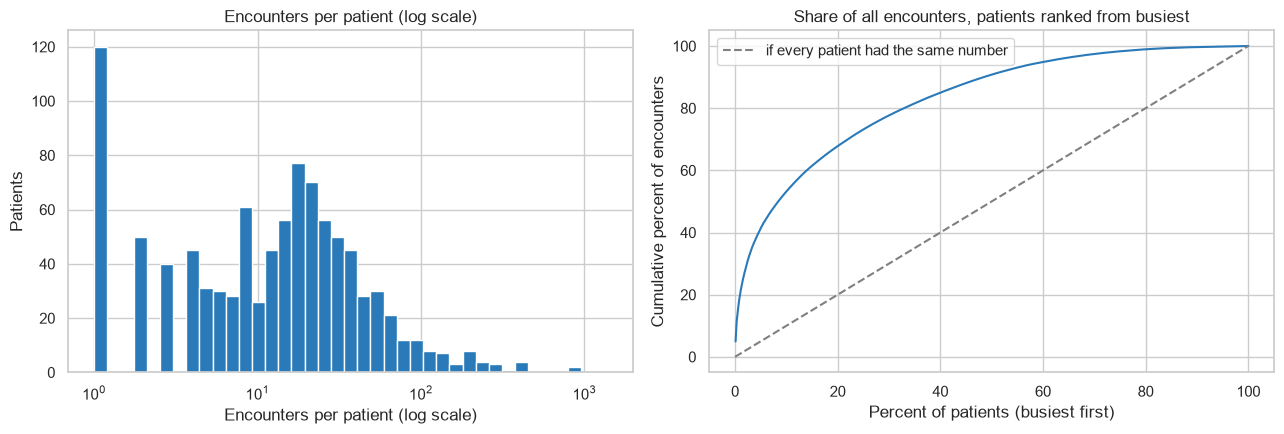

In [10]:
counts = enc.groupby("patient_id").size().sort_values(ascending=False)
print(f"Patients: {len(counts):,} | median encounters per patient: {counts.median():.0f} | maximum: {counts.iloc[0]:,}")
print(f"Busiest patient: {counts.iloc[0] / len(enc) * 100:.1f}% of all encounters")
print(f"Busiest 10 patients: {counts.iloc[:10].sum() / len(enc) * 100:.1f}% of all encounters")
print(f"Patients with 100 or more encounters: {(counts >= 100).sum()}")

cum = counts.cumsum() / counts.sum() * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(counts, bins=np.logspace(0, np.log10(counts.max()), 40), color="#2a7ab9")
ax[0].set_xscale("log")
ax[0].set_title("Encounters per patient (log scale)")
ax[0].set_xlabel("Encounters per patient (log scale)")
ax[0].set_ylabel("Patients")
ax[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values, color="#2a7ab9")
ax[1].plot([0, 100], [0, 100], color="grey", ls="--", label="if every patient had the same number")
ax[1].set_title("Share of all encounters, patients ranked from busiest")
ax[1].set_xlabel("Percent of patients (busiest first)")
ax[1].set_ylabel("Cumulative percent of encounters")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG / "fig05_encounters_per_patient.png", dpi=150)
plt.show()

**What the output shows**

- The median patient has 14 encounters, but the busiest patient has 1,381 (5.0% of all encounters), the busiest 10 patients have 20.6%, and 44 patients have 100 or more.
- In the right-hand chart, the curve bows far above the diagonal, meaning a small share of patients produces a large share of encounters.

**What it means:** tests that treat each encounter as independent will overstate how much information the data contain, because the same people appear many times. This is checked with two sensitivity analyses in Section 4.1. It is the main statistical limitation of this dataset.

### 3.7 Claim cost by insurance status

,n,median,mean
coverage_group,,,
Insured,19084,236.98,2738.16
Uninsured (NO_INSURANCE),8807,920.81,5593.20


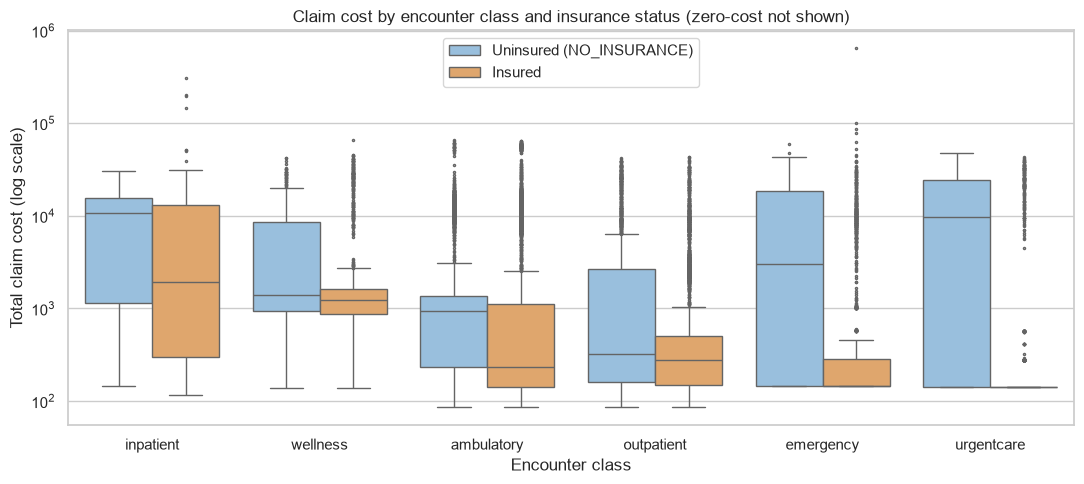

Share of each class that is insured:
encounter_class
inpatient     70.7
wellness      82.5
ambulatory    64.5
outpatient    74.1
emergency     76.1
urgentcare    59.1


In [11]:
enc["coverage_group"] = np.where(enc.is_insured, "Insured", "Uninsured (NO_INSURANCE)")
med = (enc.groupby("coverage_group")["total_claim_cost"].agg(n="size", median="median", mean="mean").round(2))
display(med)

pos = enc[enc.total_claim_cost > 0]
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=pos, x="encounter_class", y="total_claim_cost", hue="coverage_group", order=order,
            palette=["#8ec1e8", "#f2a65a"], fliersize=1.5, linewidth=1, ax=ax)
ax.set_yscale("log")
ax.set_xlabel("Encounter class")
ax.set_ylabel("Total claim cost (log scale)")
ax.set_title("Claim cost by encounter class and insurance status (zero-cost not shown)")
ax.legend(title="")
plt.tight_layout()
plt.savefig(FIG / "fig06_cost_insured_vs_uninsured.png", dpi=150)
plt.show()

print("Share of each class that is insured:")
print((enc.groupby("encounter_class")["is_insured"].mean() * 100).round(1).loc[order].to_string())

**What the output shows**

- Uninsured encounters (payer `NO_INSURANCE`) have a higher median cost (920.81) than insured encounters (236.98), and a higher mean (5,593.20 against 2,738.16).
- The uninsured median is higher in **every** class.
- The share of encounters that are insured differs by class, from 59.1% (urgent care) to 82.5% (wellness). Class mix therefore differs by insurance status, so H3 also compares within each class.

**What it cannot establish:** that being uninsured causes higher cost. Insurance status is not assigned at random, and the data hold no information on illness severity or services delivered.

## 4. Hypothesis tests

All tests use a 5% significance level (alpha = 0.05). With nearly 28,000 encounters, even very small differences produce tiny p-values, so each result is judged by its **effect size** as well as its p-value. Very small p-values underflow to zero in floating-point arithmetic and are shown as "< 1e-300".

### 4.1 H1: claim cost differs across encounter classes

| | |
|---|---|
| **Null hypothesis (H0)** | The distribution of claim cost is the same in all six encounter classes |
| **Alternative (H1)** | In at least one class, claim cost tends to be higher or lower than in another |
| **Variables** | Outcome: `total_claim_cost` (continuous). Group: `encounter_class` (6 groups) |
| **Method** | Kruskal-Wallis test, with epsilon-squared as the effect size. Follow-up: pairwise Mann-Whitney tests with Holm correction for the 15 comparisons |

**Why this method:** a standard one-way ANOVA assumes roughly normal data with similar spread in every group. Section 3.1 already showed that costs are extremely skewed and clustered, and the next cell tests both assumptions formally.

**Assumptions of Kruskal-Wallis:** (1) observations are independent, which is only partly true here because patients repeat, so it is checked with sensitivity analyses; (2) the outcome can be ranked, which holds; (3) if the result is to be read as a difference in medians, the group shapes must be similar. They are not (Section 3.2), so the result is interpreted as a difference in the **tendency to be higher or lower**, measured by the probability that a random encounter from one class costs more than one from another.

In [12]:
groups = [d["total_claim_cost"].values for _, d in enc.groupby("encounter_class")]

# Why not a standard ANOVA? Check its two main assumptions.
sample5k = enc["total_claim_cost"].sample(5000, random_state=RANDOM_STATE)
sh_raw = stats.shapiro(sample5k)
sh_log = stats.shapiro(np.log1p(sample5k))
lev = stats.levene(*groups, center="median")
print(f"Normality (Shapiro-Wilk, random 5,000): raw cost W={sh_raw.statistic:.3f}, p {p_text(sh_raw.pvalue)}")
print(f"Normality after log transform         : W={sh_log.statistic:.3f}, p {p_text(sh_log.pvalue)}")
print(f"Equal spread across classes (Levene)  : statistic={lev.statistic:.1f}, p {p_text(lev.pvalue)}")
print("Group sizes:", dict(zip(sorted(enc.encounter_class.unique()), [len(g) for g in groups])))

Normality (Shapiro-Wilk, random 5,000): raw cost W=0.459, p = 7.50e-82
Normality after log transform         : W=0.887, p = 2.87e-51
Equal spread across classes (Levene)  : statistic=159.2, p = 2.33e-167
Group sizes: {'ambulatory': 12537, 'emergency': 2322, 'inpatient': 1135, 'outpatient': 6300, 'urgentcare': 3666, 'wellness': 1931}


**Reading the assumption checks:** the data fail both ANOVA assumptions. Normality is rejected strongly (W = 0.459 on the raw costs and still only 0.887 after a log transform), and the spread differs across classes (Levene statistic 159.2). This confirms that ANOVA would be inappropriate and that a rank-based test is the right choice.

Kruskal-Wallis: H = 2,025.2, df = 5, p < 1e-300
Effect size (epsilon-squared) = 0.073   (rules of thumb: 0.01 small, 0.06 medium, 0.14 large)


,class_A,class_B,p_raw,prob_A_higher,p_holm,significant
0,ambulatory,emergency,6.44e-01,0.503,6.44e-01,False
1,ambulatory,inpatient,1.29e-153,0.264,1.42e-152,True
2,ambulatory,outpatient,5.53e-29,0.550,3.32e-28,True
3,ambulatory,urgentcare,2.69e-16,0.544,1.35e-15,True
4,ambulatory,wellness,2.22e-209,0.283,3.11e-208,True
5,emergency,inpatient,1.87e-125,0.260,1.31e-124,True
6,emergency,outpatient,1.66e-07,0.463,3.32e-07,True
7,emergency,urgentcare,5.14e-150,0.692,5.14e-149,True
8,emergency,wellness,3.75e-147,0.274,3.38e-146,True
9,inpatient,outpatient,4.10e-162,0.752,4.92e-161,True


Pairs NOT significantly different after correction: [['ambulatory', 'emergency']]


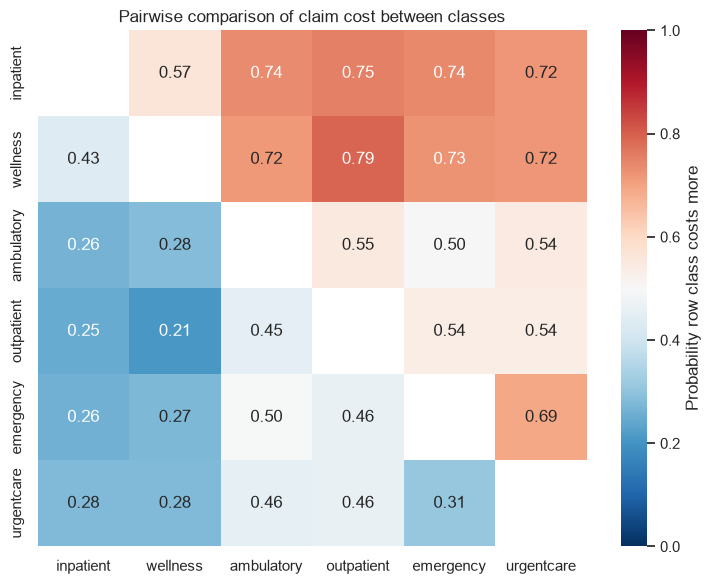

In [13]:
H, p = stats.kruskal(*groups)
n = len(enc)
eps2 = epsilon_squared(H, n)
print(f"Kruskal-Wallis: H = {H:,.1f}, df = {len(groups) - 1}, p {p_text(p)}")
print(f"Effect size (epsilon-squared) = {eps2:.3f}   (rules of thumb: 0.01 small, 0.06 medium, 0.14 large)")
results["H1"] = dict(test="Kruskal-Wallis", statistic=H, p=p, effect=eps2, n=n)

# Post-hoc: every pair of classes, Holm-corrected for 15 comparisons
classes = sorted(enc.encounter_class.unique())
rows = []
for a, b in combinations(classes, 2):
    x = enc.loc[enc.encounter_class == a, "total_claim_cost"]
    y = enc.loc[enc.encounter_class == b, "total_claim_cost"]
    u, pv = stats.mannwhitneyu(x, y, alternative="two-sided")
    rows.append((a, b, pv, u / (len(x) * len(y))))
pairs = pd.DataFrame(rows, columns=["class_A", "class_B", "p_raw", "prob_A_higher"])
pairs["p_holm"] = multipletests(pairs.p_raw, method="holm")[1]
pairs["significant"] = pairs.p_holm < ALPHA
display(pairs.assign(p_raw=pairs.p_raw.map(fmt_p), p_holm=pairs.p_holm.map(fmt_p),
                     prob_A_higher=pairs.prob_A_higher.round(3)))
print("Pairs NOT significantly different after correction:",
      pairs.loc[~pairs.significant, ["class_A", "class_B"]].values.tolist())

# Heatmap: probability that a random encounter in the row class costs more than one in the column class
mat = pd.DataFrame(np.nan, index=order, columns=order)
for _, r in pairs.iterrows():
    mat.loc[r.class_A, r.class_B] = r.prob_A_higher
    mat.loc[r.class_B, r.class_A] = 1 - r.prob_A_higher
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(mat.astype(float), annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, vmin=0, vmax=1,
            cbar_kws={"label": "Probability row class costs more"}, ax=ax)
ax.set_title("Pairwise comparison of claim cost between classes")
ax.grid(False)
plt.tight_layout()
plt.savefig(FIG / "fig07_pairwise_class_comparison.png", dpi=150)
plt.show()

**Results in plain language**

- Kruskal-Wallis: H = 2,025.2 on 5 degrees of freedom, p < 1e-300. We **reject H0**: claim cost differs across encounter classes.
- Effect size: epsilon-squared = 0.073, a **medium** effect by common rules of thumb (0.01 small, 0.06 medium, 0.14 large). Encounter class accounts for roughly 7% of the variation in cost ranks. The effect is real and moderate, not overwhelming.
- Pairwise: after Holm correction, **14 of 15 pairs differ**. The only pair that does not is **ambulatory versus emergency** (probability 0.503, essentially a coin flip, p = 0.64).
- The largest contrasts: a random inpatient encounter costs more than a random outpatient one 75% of the time and more than a random urgent care one 72% of the time. A random emergency encounter costs more than an urgent care one 69% of the time. A wellness encounter costs more than an outpatient one 79% of the time.
- Some differences are small even though they are significant, for example ambulatory versus outpatient (0.55), where a random ambulatory encounter costs more only slightly more often than not.

**Practical significance:** class matters, and knowing the class is useful when comparing or forecasting cost. It leaves most of the variation unexplained (about 93%), so class alone is not a good predictor of an individual encounter's cost.

**What it cannot establish:** why classes differ. The test shows an association with class, not what drives cost within a class.

In [14]:
# Sensitivity 1: remove the ten busiest patients (they account for a fifth of all encounters)
top10 = enc.groupby("patient_id").size().nlargest(10).index
e2 = enc[~enc.patient_id.isin(top10)]
H2, p2 = stats.kruskal(*[d["total_claim_cost"].values for _, d in e2.groupby("encounter_class")])
print(f"Without the 10 busiest patients: n={len(e2):,}, H={H2:,.1f}, p {p_text(p2)}, epsilon-squared={epsilon_squared(H2, len(e2)):.3f}")

# Sensitivity 2: one value per patient and class (that patient's median cost in the class)
pc = enc.groupby(["patient_id", "encounter_class"])["total_claim_cost"].median().reset_index()
H3, p3 = stats.kruskal(*[d["total_claim_cost"].values for _, d in pc.groupby("encounter_class")])
print(f"One value per patient and class : n={len(pc):,}, H={H3:,.1f}, p {p_text(p3)}, epsilon-squared={epsilon_squared(H3, len(pc)):.3f}")

compare = pd.DataFrame({
    "median, all encounters": enc.groupby("encounter_class")["total_claim_cost"].median(),
    "median, per patient and class": pc.groupby("encounter_class")["total_claim_cost"].median(),
    "patients with this class": pc.groupby("encounter_class").size(),
}).loc[order].round(2)
display(compare)
results["H1_sens"] = dict(excl_top10=(H2, p2, epsilon_squared(H2, len(e2))), per_patient=(H3, p3, epsilon_squared(H3, len(pc))))

Without the 10 busiest patients: n=22,132, H=2,204.7, p < 1e-300, epsilon-squared=0.100
One value per patient and class : n=2,393, H=363.0, p = 2.72e-76, epsilon-squared=0.152


,"median, all encounters","median, per patient and class",patients with this class
encounter_class,,,
inpatient,2355.59,2527.43,153
wellness,1231.44,1138.30,209
ambulatory,573.98,234.72,695
outpatient,278.58,278.58,624
emergency,146.18,2757.73,465
urgentcare,142.58,278.58,247


**Sensitivity to repeated patients**

- Removing the 10 busiest patients (a fifth of all encounters): H = 2,204.7, epsilon-squared = 0.100. The result holds and the effect is slightly larger.
- Using one value per patient and class (that patient's median cost in the class, 2,393 values): H = 363.0, p = 2.72e-76, epsilon-squared = 0.152. The result holds, with a larger effect.

So the conclusion that **cost differs by class is robust** to the repetition of patients.

However, the **ranking of classes is not**. At the encounter level the cheapest classes are urgent care (142.58) and emergency (146.18). At the patient-and-class level their medians are 278.58 and 2,757.73. This suggests that a minority of frequent patients contribute many low-cost encounters in some classes, while the typical patient's emergency visit costs more. Which class looks "cheapest" therefore depends on whether encounters or patients are the unit, and reports should say which one they use.

### 4.2 H2: claim cost is associated with encounter duration

| | |
|---|---|
| **Null hypothesis (H0)** | There is no monotonic association between duration and claim cost (Spearman rho = 0) |
| **Alternative (H1)** | There is a monotonic association (rho is not 0) |
| **Variables** | `duration_hours` and `total_claim_cost`, valid durations only (27,887 encounters) |
| **Method** | Spearman rank correlation, with an approximate 95% confidence interval (Fisher z) |

**Why this method:** both variables are heavily skewed with extreme values. Spearman works on ranks, so extreme values have limited influence, and it detects any steadily rising or falling relationship without requiring a straight line. Pearson correlation would be dominated by a few extreme encounters.

**Assumptions:** (1) each pair of values comes from the same encounter, which holds; (2) the relationship is monotonic, which the figure in Section 3.5 supports within classes; (3) observations are independent, which is only partly true (repeated patients); (4) ties are handled with average ranks. There are many ties (69% of durations are identical), which reduces the information in duration.

**Confounding:** duration is largely set by class, so the overall correlation is also computed **within each class** and as a class-adjusted rank correlation. Rules of thumb for the size of rho: 0.1 small, 0.3 medium, 0.5 large.

All valid encounters (n=27,887): Spearman rho = 0.339, 95% CI (0.327, 0.349), p < 1e-300


,class,n,distinct_durations,rho,ci_low,ci_high,p
0,inpatient,1135,59,0.173,0.113,0.233,4.09e-09
1,wellness,1931,1,NaN,NaN,NaN,n/a
2,ambulatory,12534,1376,0.478,0.463,0.492,< 1e-300
3,outpatient,6299,444,0.394,0.371,0.416,9.85e-233
4,emergency,2322,38,0.166,0.124,0.208,8.59e-16
5,urgentcare,3666,1,NaN,NaN,NaN,n/a


Class-adjusted rank correlation (ranks centred within each class): 0.392


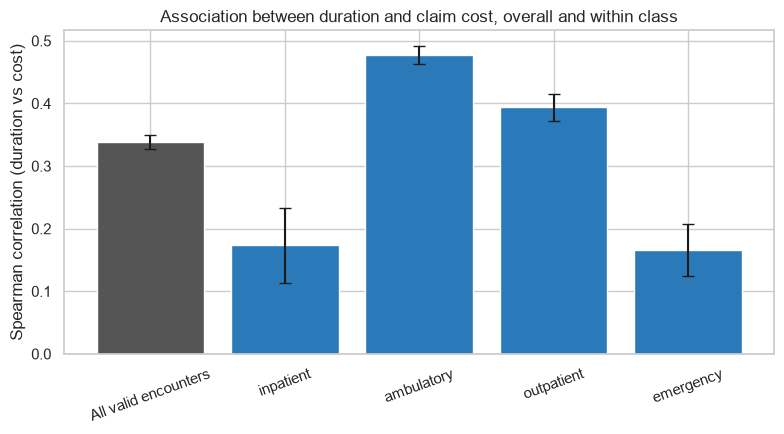

In [15]:
valid = enc[enc.duration_valid].copy()

# Overall association
rho, p = stats.spearmanr(valid["duration_hours"], valid["total_claim_cost"])
lo, hi = spearman_ci(rho, len(valid))
print(f"All valid encounters (n={len(valid):,}): Spearman rho = {rho:.3f}, 95% CI ({lo:.3f}, {hi:.3f}), p {p_text(p)}")
results["H2"] = dict(test="Spearman correlation", statistic=rho, p=p, ci=(lo, hi), n=len(valid))

# Duration depends heavily on class, so look inside each class too
rows = []
for c in order:
    d = valid[valid.encounter_class == c]
    if d["duration_hours"].nunique() < 3:
        rows.append((c, len(d), d["duration_hours"].nunique(), np.nan, np.nan, np.nan, np.nan))
        continue
    r, pv = stats.spearmanr(d["duration_hours"], d["total_claim_cost"])
    l, h = spearman_ci(r, len(d))
    rows.append((c, len(d), d["duration_hours"].nunique(), r, l, h, pv))
within = pd.DataFrame(rows, columns=["class", "n", "distinct_durations", "rho", "ci_low", "ci_high", "p"])
display(within.assign(p=within.p.map(lambda v: "n/a" if pd.isna(v) else fmt_p(v))).round(3))

# One summary number that removes class differences: rank within class, centre, then correlate
rd = valid["duration_hours"].rank()
rc = valid["total_claim_cost"].rank()
rd = rd - rd.groupby(valid.encounter_class).transform("mean")
rc = rc - rc.groupby(valid.encounter_class).transform("mean")
adj = np.corrcoef(rd, rc)[0, 1]
print(f"Class-adjusted rank correlation (ranks centred within each class): {adj:.3f}")
results["H2_adj"] = adj

plot = within.dropna(subset=["rho"])
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["All valid encounters"] + plot["class"].tolist()
vals = [rho] + plot["rho"].tolist()
errs = [[rho - lo] + (plot["rho"] - plot["ci_low"]).tolist(), [hi - rho] + (plot["ci_high"] - plot["rho"]).tolist()]
ax.bar(labels, vals, yerr=errs, color=["#555555"] + ["#2a7ab9"] * len(plot), capsize=4)
ax.set_ylabel("Spearman correlation (duration vs cost)")
ax.set_title("Association between duration and claim cost, overall and within class")
ax.axhline(0, color="black", lw=0.8)
plt.setp(ax.get_xticklabels(), rotation=20)
plt.tight_layout()
plt.savefig(FIG / "fig08_duration_cost_correlation_by_class.png", dpi=150)
plt.show()

**Results in plain language**

- Overall: rho = 0.339 (95% CI 0.327 to 0.349), p < 1e-300. We **reject H0**: longer encounters tend to cost more. The size is **medium**.
- Within classes the association persists, so it is not just a class effect: ambulatory rho = 0.478, outpatient 0.394, inpatient 0.173 (CI 0.113 to 0.233), emergency 0.166 (CI 0.124 to 0.208).
- The class-adjusted rank correlation is 0.392, which is similar to the overall value.
- It is stronger where durations vary most (ambulatory has 1,376 distinct durations, outpatient 444) and weaker where they are confined to a narrow range (inpatient 59, emergency 38).
- Wellness and urgent care cannot be tested: every encounter lasts exactly 15 minutes, so there is nothing to correlate.

**Practical significance:** a correlation of about 0.34 means duration and cost rank together in a moderate way, but with a lot of scatter. Roughly 11% of the variation in cost ranks is shared with duration (rho squared), so duration is a weak basis for predicting the cost of a single encounter.

**What it cannot establish:** that duration causes cost. Longer encounters probably involve more services, and both duration and cost may follow from what was done. The data do not contain the services delivered or clinical severity.

### 4.3 H3: claim cost differs between insured and uninsured encounters

| | |
|---|---|
| **Null hypothesis (H0)** | The distribution of claim cost is the same for insured and uninsured encounters |
| **Alternative (H1)** | Claim cost tends to be higher or lower for one group |
| **Variables** | `total_claim_cost`; group from `is_insured` (payer `NO_INSURANCE` versus any other payer) |
| **Method** | Mann-Whitney U test, with the probability of superiority as the effect size, then the same test within each class (Holm-corrected for 6 comparisons) |

**Why this method:** two independent groups and a very skewed outcome, so a rank-based test is appropriate. Assumptions: independence (partly violated, as above) and a rankable outcome. Rules of thumb for the probability of superiority: 0.56 small, 0.64 medium, 0.71 large.

In [16]:
unins = enc.loc[~enc.is_insured, "total_claim_cost"]
ins = enc.loc[enc.is_insured, "total_claim_cost"]
U, p = stats.mannwhitneyu(unins, ins, alternative="two-sided")
prob = U / (len(unins) * len(ins))
print(f"Uninsured n={len(unins):,}, median {unins.median():,.2f} | insured n={len(ins):,}, median {ins.median():,.2f}")
print(f"Mann-Whitney U = {U:,.0f}, p {p_text(p)}")
print(f"Probability that a random uninsured encounter costs more than a random insured one: {prob:.3f}")
results["H3"] = dict(test="Mann-Whitney U", statistic=U, p=p, effect=prob, n=len(enc))

# Does the same direction hold inside every class?
rows = []
for c in order:
    d = enc[enc.encounter_class == c]
    a = d.loc[~d.is_insured, "total_claim_cost"]
    b = d.loc[d.is_insured, "total_claim_cost"]
    uu, pv = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append((c, len(a), len(b), a.median(), b.median(), uu / (len(a) * len(b)), pv))
h3_class = pd.DataFrame(rows, columns=["class", "n_uninsured", "n_insured", "median_uninsured",
                                       "median_insured", "prob_uninsured_higher", "p"])
h3_class["p_holm"] = multipletests(h3_class.p, method="holm")[1]
display(h3_class.assign(p=h3_class.p.map(fmt_p), p_holm=h3_class.p_holm.map(fmt_p)).round(3))

Uninsured n=8,807, median 920.81 | insured n=19,084, median 236.98
Mann-Whitney U = 104,844,580, p = 2.45e-244
Probability that a random uninsured encounter costs more than a random insured one: 0.624


,class,n_uninsured,n_insured,median_uninsured,median_insured,prob_uninsured_higher,p,p_holm
0,inpatient,332,803,10600.005,1689.71,0.609,7.60e-09,1.52e-08
1,wellness,337,1594,1388.110,1200.30,0.581,3.04e-06,3.04e-06
2,ambulatory,4453,8084,936.270,234.72,0.615,4.49e-101,2.25e-100
3,outpatient,1631,4669,319.200,278.58,0.574,3.19e-19,9.56e-19
4,emergency,555,1767,2879.930,146.18,0.698,2.75e-56,1.10e-55
5,urgentcare,1499,2167,9607.290,142.58,0.735,4.59e-177,2.76e-176


**Results in plain language**

- Uninsured median 920.81 against insured median 236.98. Mann-Whitney U = 104,844,580, p = 2.45e-244. We **reject H0**.
- A randomly chosen uninsured encounter costs more than a randomly chosen insured one with probability **0.624**, a **small-to-medium** effect.
- Inside every class the uninsured group is higher, with probabilities between 0.57 and 0.74, and all six are significant after Holm correction. The gap is largest in urgent care (0.735) and emergency (0.698) and smallest in outpatient (0.574) and wellness (0.581). So the difference is not just a result of the two groups having different class mixes.

**Practical significance:** the effect is moderate and consistent in direction, which makes it worth reviewing. But the median difference in outpatient and wellness is small in money terms (319 against 279, and 1,388 against 1,200).

**What it cannot establish:** that being uninsured causes higher cost. The groups may differ in case mix, severity or services delivered, none of which are in the data, and costs may be recorded or charged differently for uninsured encounters. By construction, all uninsured encounters also have zero recorded payer coverage.

## 5. Limitations

| Limitation | Effect on the conclusions | What was done |
|---|---|---|
| **Repeated patients.** 974 patients, median 14 encounters, one patient with 1,381 | Tests assume independent observations. P-values are too optimistic and effect sizes may be affected | Two sensitivity analyses (without the 10 busiest patients, and one value per patient and class). H1 held in both, but the ranking of classes changed |
| **Unequal group sizes.** 1,135 to 12,537 per class | Pairwise tests have more power for large classes. Small classes are estimated less precisely | Rank-based tests that handle unequal sizes. Group sizes shown on the figures |
| **Many tied values.** 13,529 distinct costs and 69% of durations identical | Reduces the information in the data. Correlation and rank tests lose some precision | Average ranks used. Within-class analysis for H2 |
| **Missing data.** None in the variables used | No bias from missingness here | Nothing imputed |
| **Zero-cost encounters (89) and extreme values** | Zeros cannot be shown on log charts. Extremes dominate means | Kept in all tests. Rank-based methods used. Zeros noted on figures |
| **Confounding.** No diagnosis, severity, services delivered or age in the analysis | Differences by class, duration and insurance may reflect things not measured | Within-class comparisons for H2 and H3. Findings described as associations |
| **Association is not causation.** | No result shows that class, duration or insurance causes cost | Wording of all results |
| **Large sample.** Nearly 28,000 encounters | Tiny differences give tiny p-values | Effect sizes reported and used to judge importance |
| **Multiple testing.** | Many tests raise the chance of a false positive | Holm correction for pairwise comparisons. The three main hypotheses are separate questions and not corrected, but all are very strongly significant |
| **Single organisation, provenance not stated.** | Findings may not apply elsewhere. Patterns such as repeated charges suggest the data may be simulated | Results described as applying to this dataset only |
| **Duration measure.** Some durations of several months pass the one-year rule | Extreme durations may be recording artefacts | Four durations over one year excluded. Rank-based method limits influence of the rest |

**No clinical claims are made.** The analysis describes recorded costs and durations only.

## 6. Summary of results and recommendations

In [17]:
h1, h2, h3 = results["H1"], results["H2"], results["H3"]
final = pd.DataFrame([
    ["H1  Claim cost differs across encounter classes", "Kruskal-Wallis", f"H = {h1['statistic']:,.1f}",
     fmt_p(h1["p"]), f"epsilon-squared = {h1['effect']:.3f} (medium)", "Reject H0"],
    ["H2  Claim cost is associated with duration", "Spearman correlation", f"rho = {h2['statistic']:.3f}",
     fmt_p(h2["p"]), f"rho = {h2['statistic']:.2f}, CI ({h2['ci'][0]:.2f}, {h2['ci'][1]:.2f}) (medium)", "Reject H0"],
    ["H3  Insured and uninsured costs differ", "Mann-Whitney U", f"U = {h3['statistic']:,.0f}",
     fmt_p(h3["p"]), f"P(uninsured higher) = {h3['effect']:.3f} (small to medium)", "Reject H0"],
], columns=["Hypothesis", "Test", "Statistic", "p-value", "Effect size", "Decision at 5%"])
final

,Hypothesis,Test,Statistic,p-value,Effect size,Decision at 5%
0,H1 Claim cost differs across encounter classes,Kruskal-Wallis,"H = 2,025.2",< 1e-300,epsilon-squared = 0.073 (medium),Reject H0
1,H2 Claim cost is associated with duration,Spearman correlation,rho = 0.339,< 1e-300,"rho = 0.34, CI (0.33, 0.35) (medium)",Reject H0
2,H3 Insured and uninsured costs differ,Mann-Whitney U,"U = 104,844,580",2.45e-244,P(uninsured higher) = 0.624 (small to medium),Reject H0


### Findings

1. **Claim cost differs by encounter class** (H1: epsilon-squared 0.073, medium). Inpatient and wellness encounters have the highest median costs, and urgent care and emergency the lowest. Urgent care and emergency also contain a minority of very expensive encounters. The result held after allowing for repeated patients, but the ordering of classes depends on whether encounters or patients are the unit.
2. **Longer encounters tend to cost more** (H2: rho 0.34, medium), including within classes (ambulatory 0.48, outpatient 0.39). The link is weaker in inpatient and emergency, whose durations vary little.
3. **Uninsured encounters tend to cost more than insured ones** (H3: probability 0.62, small to medium), in every class, most clearly in urgent care and emergency.
4. **Costs are very skewed.** The mean is 13 times the median, and the top 5% of encounters carry 44.6% of cost.

### Recommendations

| # | Recommendation | Supported by | Limitation |
|---|---|---|---|
| 1 | Report claim cost as medians and distributions, never means alone, and always say whether encounters or patients are the unit | Sections 3.1, 3.3, 4.1 sensitivity | Medians hide the expensive minority, so report the upper range too |
| 2 | Compare cost across years, payers or sites only after accounting for encounter class mix | H1 (class explains a medium share of variation) | Class explains only about 7% of rank variation, so other drivers matter |
| 3 | Review billing and cost recording for uninsured encounters in urgent care and emergency, where the gap is largest | H3 within-class results | Cannot show cause. Case mix and recording differences are possible |
| 4 | Before building any cost prediction model, add the missing information: diagnosis or severity, services delivered, and claim status | Sections 4.1 to 4.3 (class, duration and insurance explain only part of cost) | Needs a richer data feed |
| 5 | Treat duration as a descriptor of class, not as an independent driver, and review unusually long encounters within ambulatory and outpatient, where duration varies most | H2 | Duration and cost may both follow from services delivered |

## 7. How to reproduce this analysis

1. Clone the repository and create the environment:
   ```
   python -m venv .venv
   source .venv/Scripts/activate      # Windows Git Bash. On macOS/Linux: source .venv/bin/activate
   pip install -r requirements.txt
   ```
2. Place the six AnalystLab Africa dataset files in `data/raw/`.
3. Build the cleaned tables:
   ```
   python src/prepare_data.py
   ```
4. Open `notebooks/track_b_analysis.ipynb`, choose the `.venv` kernel, and use **Run All**. Figures are written to `docs/figures/`.

A fixed random seed (42) is used wherever random sampling occurs, so repeated runs give the same results. The library versions used are printed at the top of the notebook.